# MSLesSeg: brain MRI dataset inspection (FLAIR, T1, T2 + lesion mask)

Dataset: **MSLesSeg** (open, CC-BY-4.0 per the dataset paper). 

## 1. Task definition (brain only)

**Input**
- One 3-D brain MRI of a person with multiple sclerosis, stored as NIfTI (Neuroimaging Informatics Technology Initiative). MSLesSeg provides three co-registered sequences per scan: **FLAIR, T1-w, T2-w**. All three are inspected here.
- Format (stated in the dataset paper, verified by this notebook): skull-stripped, affinely registered to the MNI152 1 mm template, shape 182 x 218 x 182, LAS orientation.

**Output**
- A binary 3-D mask with the same shape, affine and orientation as the input: `1` = voxel belongs to an MS white-matter lesion, `0` = everything else. In MSLesSeg the masks were drawn on the registered FLAIR, with T1 and T2 used to resolve ambiguities.
- For *detection* metrics, lesion instances are derived from the mask as 26-connected components.

**Evaluation**: Dice, lesion-wise recall and false positives per patient, absolute volume difference. Patient-level splits only.

**Out of scope**: spinal cord and optic nerve lesions, other brain pathologies, lesion sub-typing (periventricular / cortical / ...), new-lesion detection between timepoints, diagnosis, EDSS prediction.

## 2. How to run
1. `pip install nibabel scipy pandas matplotlib openpyxl`
2. Point `MSLESSEG_ROOT` below (or the env var of the same name) at the folder containing the unzipped dataset.

## 0. What changed in this revision (v2)
The first run printed several odd numbers. They came from the notebook, not from the dataset:

| Symptom in v1 | Cause | Fix in v2 |
|---|---|---|
| 233 series, 118 in split `unknown` with 0 masks, shapes like (512,512,81), 5 timepoints for one patient | `rglob` also picked up a second copy of the scans in **native scanner space** (no masks, not registered, not skull-stripped). Only the 115 files per sequence on the 182x218x182 MNI grid are the released MSLesSeg data. | Every file's header is read first; files not on the MNI grid are reported separately and excluded from the analysis. |
| `clinical_data.csv` loaded as shape (115, 1), "no scanner/field-strength column" | The file is **semicolon-separated with decimal commas**, `pd.read_csv` used `,`. Also only the first CSV was read; the three `patient_scanners_info_*.csv` files were never opened. | Delimiter/decimal auto-detection, all metadata CSVs are loaded, clinical lesion volume/count is cross-checked against the masks. |
| T1: 83/115 "suspicious", median brain intensity 3 to 1865 (621x), lesion voxels at T1 = 0 in 14 masks (worst 100 %), FLAIR/T1 brain Dice min 0.000 | (a) brain = `v > 0` breaks on volumes with negative values/background noise and on a blank volume; (b) `contrast_z` against the *whole brain* mean and the left-right mirror test are not valid for T1/T2 (CSF is bright on T2, dark on T1; lesions are bilateral and periventricular so the mirror lands on similar tissue). | brain = `v != 0`; local ring contrast (robust median/MAD); registration checked with FLAIR-to-T1/T2 normalised mutual information vs a shifted copy; blank volumes are flagged explicitly and listed. |
| The list of "suspicious" cases only shows test patients | `complete` was sorted as strings (`test` < `train`, `P54` < `P6`). | Natural sort by patient number. |
| Lesion count differs from the paper (27.2 vs 28.9, 39.7 vs 41.2) | The paper does not state the connectivity used. 26-connectivity merges touching lesions. | Counts reported for 6-, 18- and 26-connectivity. |
| Volume SD differs slightly (13.31 vs 13.233) | The paper uses the population SD (ddof=0), pandas defaults to ddof=1. | Comparison uses ddof=0. |

In [1]:
import os, re, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import nibabel as nib
from scipy import ndimage
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 180, "display.max_colwidth", 60)

MSLESSEG_ROOT = Path(os.environ.get("MSLESSEG_ROOT", "data/MSLesSeg"))
OUT = Path(os.environ.get("INSPECTION_OUT", "inspection_output")); OUT.mkdir(exist_ok=True)

SEQS = ["FLAIR", "T1", "T2"]
EXPECTED_SHAPE = (182, 218, 182)      # stated in the MSLesSeg paper (MNI152 1 mm grid)
EXPECTED_ORIENT = "LAS"               # stated in the MSLesSeg paper
TINY_MM3 = 14.0                       # lesions below this volume (~3 mm diameter sphere) count as "small"; adjust freely

# --- QC thresholds (heuristics, adjust freely) ---
BRAIN_DICE_MIN   = 0.95               # minimum agreement of the brain footprint between two sequences before we flag it
MIN_BRAIN_VOX    = 300_000            # a skull-stripped adult brain on the 1 mm MNI grid has ~1.2-1.8 M non-zero voxels; far fewer = blank/corrupt
MASK_IN_BRAIN_MIN = 0.99              # flag a sequence if < 99 % of lesion voxels fall on non-zero image voxels (v1 flagged 99.96 %, which is noise)
RING_VOX         = 3                  # width of the reference ring around each lesion set for the local-contrast metric
SHIFT_VOX        = 4                  # displacement used by the registration (NMI) control
NMI_GAIN_MIN     = 0.0                # NMI(aligned) - NMI(shifted) must exceed this

STRUCT26 = ndimage.generate_binary_structure(3, 3)   # 26-connectivity
STRUCTS  = {6: ndimage.generate_binary_structure(3, 1),
            18: ndimage.generate_binary_structure(3, 2),
            26: STRUCT26}

# Numbers published in the dataset paper (Scientific Data 12:920, 2025), used only for cross-checks
PAPER = dict(patients=75, series=115, train_patients=53, train_series=93, test_patients=22, test_series=22,
             tp_hist={1: 50, 2: 15, 3: 5, 4: 5},
             table1={"train": dict(vol=(12.167, 13.233), n=(28.9, 19.2)),
                     "test":  dict(vol=(10.231, 10.912), n=(41.2, 43.17))})

print("nibabel", nib.__version__)
print("MSLesSeg root:", MSLESSEG_ROOT.resolve())

nibabel 5.5.0
MSLesSeg root: /home/jovyan/AAI/data/MSLesSeg


## 3. Helper functions

In [2]:
def axcodes(img):
    return "".join(nib.aff2axcodes(img.affine))

def load_vol(path):
    img = nib.load(str(path))
    return img, np.asarray(img.dataobj, dtype=np.float32)

def load_mask(path):
    img = nib.load(str(path))
    return img, np.asarray(img.dataobj)

def header_info(path):
    img = nib.load(str(path))
    return dict(shape=tuple(int(x) for x in img.shape),
                zooms=tuple(round(float(z), 3) for z in img.header.get_zooms()[:3]),
                orient=axcodes(img), dtype=str(img.get_data_dtype()))

def lesion_components(mask_bool, structure=STRUCT26):
    lab, n = ndimage.label(mask_bool, structure=structure)
    sizes = np.bincount(lab.ravel())[1:] if n else np.zeros(0, dtype=int)
    return lab, int(n), sizes

def brain_of(v):
    """Skull-stripped volumes are 0 outside the brain. Use != 0 (not > 0): some volumes contain negative values
    after interpolation / intensity shifting, and `> 0` silently drops them (v1 bug)."""
    return np.isfinite(v) & (v != 0)

def local_contrast_z(vol, mask_bool, brain_bool, ring_vox=RING_VOX):
    """Robust local lesion contrast: (median inside lesions - median in a ring around them) / (1.4826 * MAD of the ring).
    Ring = voxels within `ring_vox` of a lesion, excluding lesions and a 1-voxel gap, inside the brain.
    Unlike a comparison with the whole-brain mean this is not dominated by CSF (bright on T2, dark on T1)."""
    if not mask_bool.any():
        return np.nan
    idx = np.nonzero(mask_bool)
    lo = [max(int(i.min()) - ring_vox - 2, 0) for i in idx]
    hi = [int(i.max()) + ring_vox + 3 for i in idx]
    sl = tuple(slice(a, b) for a, b in zip(lo, hi))
    m, v, b = mask_bool[sl], vol[sl], brain_bool[sl]
    near = ndimage.binary_dilation(m, iterations=1)
    far = ndimage.binary_dilation(m, iterations=ring_vox)
    ring = far & ~near & b
    inside = m & b
    if inside.sum() == 0 or ring.sum() < 50:
        return np.nan
    r = v[ring]
    mad = 1.4826 * np.median(np.abs(r - np.median(r)))
    return float((np.median(v[inside]) - np.median(r)) / mad) if mad > 0 else np.nan

def nmi(a, b, bins=48):
    """Normalised mutual information (Hx+Hy)/Hxy of two 1-D intensity samples; higher = better aligned."""
    la, ha = np.percentile(a, [1, 99]); lb, hb = np.percentile(b, [1, 99])
    if ha <= la or hb <= lb:
        return np.nan
    h, _, _ = np.histogram2d(np.clip(a, la, ha), np.clip(b, lb, hb), bins=bins)
    p = h / h.sum(); px, py = p.sum(1), p.sum(0)
    ent = lambda q: -(q[q > 0] * np.log(q[q > 0])).sum()
    return float((ent(px) + ent(py)) / ent(p))

def nmi_gain(ref, mov, brain, shift=SHIFT_VOX, step=3):
    """NMI(ref, mov) minus the mean NMI after displacing `mov` by +-shift voxels along each axis.
    A properly co-registered pair loses information when displaced, so the gain is clearly > 0.
    Mask-independent: because the masks were drawn on FLAIR, FLAIR-vs-T1/T2 registration is what decides whether
    the mask also fits T1/T2."""
    flat = np.flatnonzero(brain.ravel())[::step]
    if flat.size < 1000:
        return np.nan, np.nan
    a = ref.ravel()[flat]
    n0 = nmi(a, mov.ravel()[flat])
    ctrl = []
    for ax in range(3):
        for s in (shift, -shift):
            ctrl.append(nmi(a, np.roll(mov, s, axis=ax).ravel()[flat]))
    return n0, float(n0 - np.nanmean(ctrl))

def dice(a, b):
    s = a.sum() + b.sum()
    return float(2 * (a & b).sum() / s) if s else np.nan

def qc_case(paths, mask_path, case_id=""):
    """All per-case checks. `paths` maps sequence name -> file.
    Mask-level statistics once; image-level statistics once per sequence (prefix FLAIR_, T1_, T2_)."""
    mimg, m = load_mask(mask_path)
    mb = m > 0
    mz = tuple(round(float(z), 3) for z in mimg.header.get_zooms()[:3])
    vox_mm3 = float(np.prod(mz))
    row = dict(case=case_id, mask_shape=tuple(m.shape), mask_zooms=mz, mask_orient=axcodes(mimg),
               mask_values=np.unique(m)[:6].tolist(),
               mask_binary=bool(set(np.unique(m).tolist()) <= {0, 1}))
    brains, flair_vol = {}, None
    for seq, p in paths.items():
        img, v = load_vol(p)
        row[f"{seq}_shape"] = tuple(v.shape)
        row[f"{seq}_zooms"] = tuple(round(float(z), 3) for z in img.header.get_zooms()[:3])
        row[f"{seq}_orient"] = axcodes(img)
        row[f"{seq}_finite"] = bool(np.isfinite(v).all())
        row[f"{seq}_shape_match"] = (v.shape == m.shape)
        row[f"{seq}_affine_match"] = bool(np.allclose(img.affine, mimg.affine, atol=1e-3))
        if v.shape != m.shape:
            continue
        brain = brain_of(v)
        brains[seq] = brain
        nz = int(brain.sum())
        row[f"{seq}_brain_vox"] = nz
        row[f"{seq}_degenerate"] = nz < MIN_BRAIN_VOX            # blank / near-empty volume
        row[f"{seq}_neg_frac"] = float((v[brain] < 0).mean()) if nz else np.nan
        row[f"{seq}_min"] = float(v.min()); row[f"{seq}_p99"] = float(np.percentile(v[brain], 99)) if nz else np.nan
        row[f"{seq}_frac_mask_in_brain"] = float((mb & brain).sum() / mb.sum()) if mb.any() else np.nan
        row[f"{seq}_median_brain"] = float(np.median(v[brain])) if nz else np.nan
        row[f"{seq}_contrast_z"] = local_contrast_z(v, mb, brain) if nz >= MIN_BRAIN_VOX else np.nan
        if seq == "FLAIR":
            # mask drawn on FLAIR: the mirrored mask must fit clearly worse than the real one
            cf = local_contrast_z(v, mb[::-1], brain) if nz >= MIN_BRAIN_VOX else np.nan
            row["FLAIR_contrast_flipLR"] = cf
            c = row["FLAIR_contrast_z"]
            row["FLAIR_align_gain"] = (abs(c) - abs(cf)) if np.isfinite(c) and np.isfinite(cf) else np.nan
            flair_vol = v
        elif flair_vol is not None and nz >= MIN_BRAIN_VOX and brains["FLAIR"].sum() >= MIN_BRAIN_VOX:
            n0, g = nmi_gain(flair_vol, v, brains["FLAIR"] & brain)
            row[f"{seq}_nmi_FLAIR"] = n0
            row[f"{seq}_align_gain"] = g
    # mask statistics (once)
    ref = brains.get("FLAIR", next(iter(brains.values()), None))
    _, n, sizes = lesion_components(mb)
    sizes_mm3 = sizes * vox_mm3
    row.update(
        brain_ml=(ref.sum() * vox_mm3 / 1000) if ref is not None else np.nan,
        lesion_ml=mb.sum() * vox_mm3 / 1000,
        lesion_pct_brain=(100 * mb.sum() / max(ref.sum(), 1)) if ref is not None else np.nan,
        n_lesions=n,                                     # 26-connectivity
        n_lesions_18=lesion_components(mb, STRUCTS[18])[1],
        n_lesions_6=lesion_components(mb, STRUCTS[6])[1],
        median_lesion_mm3=float(np.median(sizes_mm3)) if n else np.nan,
        frac_small=float((sizes_mm3 < TINY_MM3).mean()) if n else np.nan,
        sizes_mm3=sizes_mm3,
    )
    for other in ("T1", "T2"):
        if "FLAIR" in brains and other in brains:
            row[f"brain_dice_FLAIR_{other}"] = dice(brains["FLAIR"], brains[other])
    return row

def plane_name(code):
    return {"L": "sagittal", "R": "sagittal", "A": "coronal", "P": "coronal",
            "S": "axial", "I": "axial"}[code]

def show_overlay_multi(vols, mask, orient, title=""):
    """Rows = sequences, columns = three planes, all through the slices with the largest lesion area."""
    mb = mask > 0
    if not mb.any():
        print(title, ": empty mask, nothing to overlay"); return
    idx = [int(np.argmax(mb.sum(axis=tuple(a for a in range(3) if a != i)))) for i in range(3)]
    fig, axs = plt.subplots(len(vols), 3, figsize=(12, 3.9 * len(vols)), squeeze=False)
    for r, (name, vol) in enumerate(vols.items()):
        nzv = vol[brain_of(vol)]
        vals = nzv if nzv.size else vol.ravel()
        vmin, vmax = np.percentile(vals, [0.5, 99.5])
        for i in range(3):
            ax = axs[r, i]
            sl = [slice(None)] * 3; sl[i] = idx[i]
            f2, m2 = vol[tuple(sl)], mb[tuple(sl)]
            ax.imshow(np.rot90(f2), cmap="gray", vmin=vmin, vmax=vmax)
            if m2.any():
                ax.contour(np.rot90(m2).astype(float), levels=[0.5], colors="r", linewidths=0.8)
            ax.set_title(f"{name} | {plane_name(orient[i])} (axis {i}, slice {idx[i]})", fontsize=8)
            ax.axis("off")
    fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()

## 4. File inventory

The challenge release used the pattern `Px/Tx/Px_Tx_{T1,T2,FLAIR,MASK}.nii.gz` for training and `Px/Px_{...}.nii.gz` for test. The pattern below accepts both.

**Important:** the folder you point `MSLESSEG_ROOT` at may contain *more than one copy* of the scans (e.g. the registered release plus the original scanner-space volumes, plus the GitHub repo with a template file). v1 mixed them together. v2 reads every header first and keeps only files on the documented 182 x 218 x 182 MNI grid; everything else is listed and set aside.

In [3]:
assert MSLESSEG_ROOT.exists(), f"{MSLESSEG_ROOT} does not exist. Set MSLESSEG_ROOT to the dataset folder."

PAT = re.compile(r"(?P<pid>P\d+)(?:_T(?P<tp>\d+))?_(?P<seq>FLAIR|T1|T2|MASK)\.nii(?:\.gz)?$", re.I)

def infer_split(p):
    parts = [x.lower() for x in p.relative_to(MSLESSEG_ROOT).parts]
    if any("train" in x for x in parts): return "train"
    if any("test" in x for x in parts): return "test"
    return "unknown"

def folder_tag(p):
    parts = [x for x in p.relative_to(MSLESSEG_ROOT).parts[:-1] if not re.fullmatch(r"P\d+|T\d+", x, re.I)]
    return "/".join(parts)

rows, unmatched = [], []
for p in sorted(MSLESSEG_ROOT.rglob("*.nii*")):
    m = PAT.search(p.name)
    if m:
        rows.append(dict(path=p, pid=m["pid"].upper(), tp=int(m["tp"]) if m["tp"] else 1,
                         seq=m["seq"].upper(), split=infer_split(p), folder=folder_tag(p)))
    else:
        unmatched.append(p)

if unmatched:
    print(f"{len(unmatched)} NIfTI files did not match the pattern (template/other files, ignored), e.g.:")
    for p in unmatched[:8]: print("   ", p)

df_all = pd.DataFrame(rows)
assert len(df_all) > 0, "No NIfTI files matched the MSLesSeg pattern. Check MSLESSEG_ROOT and the regex."

# Read every header once (cheap) and decide which files are the registered MSLesSeg release.
hdr_all = pd.DataFrame([header_info(p) for p in df_all.path])
df_all = pd.concat([df_all.reset_index(drop=True), hdr_all], axis=1)
df_all["space"] = np.where(df_all["shape"] == EXPECTED_SHAPE, "mni_1mm", "native")

print("\nFiles by folder and grid (mni_1mm = registered release, native = anything else):")
print(df_all.groupby(["folder", "split", "space"]).agg(files=("path", "size"), patients=("pid", "nunique")).to_string())

df_native = df_all[df_all.space == "native"].copy()
df_files = df_all[df_all.space == "mni_1mm"].copy()
print(f"\nKept for analysis : {len(df_files)} files on the {EXPECTED_SHAPE} grid")
print(f"Set aside         : {len(df_native)} files NOT on that grid "
      f"({df_native.seq.value_counts().to_dict()}; masks among them: {int((df_native.seq == 'MASK').sum())})")
if len(df_native):
    print("   -> these are not the released training/test volumes (no masks, not registered); excluded from every check below.")
    df_native.assign(path=df_native.path.astype(str)).to_csv(OUT / "mslesseg_native_space_files.csv", index=False)

# If the folder tree does not say train/test, fall back to the patient-number rule in the paper
# (training = patients 1-53, test = 54-75). This is an ASSUMPTION; verify against the overview file.
unk = df_files.split == "unknown"
if unk.any():
    df_files.loc[unk, "split"] = np.where(df_files.loc[unk, "pid"].str[1:].astype(int) <= 53, "train", "test")
    print(f"NOTE: {int(unk.sum())} files had no train/test folder; assigned by patient number (<=53 train). Verify this.")

ndup = int(df_files.duplicated(subset=["split", "pid", "tp", "seq"]).sum())
if ndup:
    print(f"WARNING: {ndup} duplicate (split, patient, timepoint, sequence) files on the MNI grid; keeping the first of each.")
df_files = df_files.drop_duplicates(subset=["split", "pid", "tp", "seq"])
wide = df_files.set_index(["split", "pid", "tp", "seq"])["path"].unstack("seq")

print("\nPatients (unique IDs)       :", df_files.pid.nunique())
print("Series / timepoints         :", len(wide))
print("Sequences found             :", sorted(set(df_files.seq) - {"MASK"}), "| masks present:", "MASK" in set(df_files.seq))
print()
print("Files present per split (rows = split, columns = sequence):")
print(wide.notna().groupby(level="split").sum())
print()
print("Patients per split:", df_files.groupby("split").pid.nunique().to_dict())
tp_counts = wide.reset_index().groupby("pid").tp.nunique().value_counts().sort_index()
print("Patients by number of timepoints:", tp_counts.to_dict())

# --- compare with the numbers printed in the paper ---
ser = wide.groupby(level="split").size().to_dict()
pat = df_files.groupby("split").pid.nunique().to_dict()
checks = [("patients", df_files.pid.nunique(), PAPER["patients"]), ("series", len(wide), PAPER["series"]),
          ("train patients", pat.get("train"), PAPER["train_patients"]), ("train series", ser.get("train"), PAPER["train_series"]),
          ("test patients", pat.get("test"), PAPER["test_patients"]), ("test series", ser.get("test"), PAPER["test_series"]),
          ("timepoint histogram", tp_counts.to_dict(), PAPER["tp_hist"])]
print("\nCheck against the dataset paper:")
for name, got, exp in checks:
    print(f"   {name:<20} got {got!s:<32} paper {exp!s:<32} {'OK' if got == exp else 'MISMATCH'}")
test_ids = sorted(int(x[1:]) for x in df_files[df_files.split == "test"].pid.unique())
if test_ids:
    print(f"   test patient numbers: {test_ids[0]}..{test_ids[-1]} ({len(test_ids)} patients)")

need = SEQS + ["MASK"]
missing_cols = [c for c in need if c not in wide.columns]
assert not missing_cols, f"Missing sequences/masks in the dataset: {missing_cols}"
incomplete = wide[wide[need].isna().any(axis=1)]
print(f"\nSeries with all of {need}: {len(wide) - len(incomplete)} / {len(wide)}")
if len(incomplete):
    print("Incomplete series (these are skipped by the QC below):")
    print(incomplete[need].notna().to_string())

1 NIfTI files did not match the pattern (template/other files, ignored), e.g.:
    data/MSLesSeg/MSLesSeg-2024-main/MSLesSeg-2024-main/resources/MNI152_T1_1mm.nii.gz

Files by folder and grid (mni_1mm = registered release, native = anything else):
                                                         files  patients
folder                                  split   space                   
MSLesSeg Dataset/MSLesSeg Dataset/test  test    mni_1mm     88        22
MSLesSeg Dataset/MSLesSeg Dataset/train train   mni_1mm    372        53
MSLesSeg_RAW                            unknown native     353        75

Kept for analysis : 460 files on the (182, 218, 182) grid
Set aside         : 353 files NOT on that grid ({'FLAIR': 118, 'T1': 118, 'T2': 117}; masks among them: 0)
   -> these are not the released training/test volumes (no masks, not registered); excluded from every check below.

Patients (unique IDs)       : 75
Series / timepoints         : 115
Sequences found             : ['FLAIR

### Are the test masks released?
The table above answers it: if the `MASK` column is non-zero for the `test` rows, test masks are in your copy. The paper says the challenge withheld them from participants, but it also reports metrics on a held-out group of patients, which suggests masks exist for those patients in the final release. Trust the table, not this sentence.

In [4]:
has_mask = wide["MASK"].notna()
print("Series with a mask, per split:")
print(has_mask.groupby(level="split").agg(["sum", "count"]).rename(columns={"sum": "with_mask", "count": "series"}))
TEST_MASKS_RELEASED = bool(has_mask.xs("test", level="split").any()) if "test" in wide.index.get_level_values("split") else False
print("\nTest masks released:", TEST_MASKS_RELEASED)

Series with a mask, per split:
       with_mask  series
split                   
test          22      22
train         93      93

Test masks released: True


## 5. Image dimensions, voxel spacing and orientation (headers only, every file, all sequences + masks)

In [5]:
inv = df_files.copy()                      # headers were already read in the inventory cell
inv.assign(path=inv.path.astype(str)).to_csv(OUT / "mslesseg_file_inventory.csv", index=False)

for seq in SEQS + ["MASK"]:
    sub = inv[inv.seq == seq]
    print(f"[{seq}] n={len(sub)}")
    print("   shapes     :", dict(Counter(sub["shape"])))
    print("   voxel size :", dict(Counter(sub["zooms"])))
    print("   orientation:", dict(Counter(sub["orient"])))
    print("   dtype      :", dict(Counter(sub["dtype"])))

shape_ok = bool(inv["shape"].map(lambda s: s == EXPECTED_SHAPE).all())
orient_ok = bool((inv["orient"] == EXPECTED_ORIENT).all())
print(f"\nAll analysed files (every sequence and mask) have the documented shape {EXPECTED_SHAPE}: {shape_ok}")
print(f"All analysed files have the documented orientation {EXPECTED_ORIENT}: {orient_ok}")

if len(df_native):
    print("\nFor reference, the excluded native-space files (original scanner grids, NOT used for modelling):")
    for seq in SEQS:
        sub = df_native[df_native.seq == seq]
        print(f"[{seq}] n={len(sub)} | {len(set(sub['shape']))} distinct shapes, {len(set(sub['zooms']))} distinct voxel sizes")

[FLAIR] n=115
   shapes     : {(182, 218, 182): 115}
   voxel size : {(1.0, 1.0, 1.0): 115}
   orientation: {'LAS': 115}
   dtype      : {'float32': 115}
[T1] n=115
   shapes     : {(182, 218, 182): 115}
   voxel size : {(1.0, 1.0, 1.0): 115}
   orientation: {'LAS': 115}
   dtype      : {'float32': 115}
[T2] n=115
   shapes     : {(182, 218, 182): 115}
   voxel size : {(1.0, 1.0, 1.0): 115}
   orientation: {'LAS': 115}
   dtype      : {'float32': 115}
[MASK] n=115
   shapes     : {(182, 218, 182): 115}
   voxel size : {(1.0, 1.0, 1.0): 115}
   orientation: {'LAS': 115}
   dtype      : {'float32': 115}

All analysed files (every sequence and mask) have the documented shape (182, 218, 182): True
All analysed files have the documented orientation LAS: True

For reference, the excluded native-space files (original scanner grids, NOT used for modelling):
[FLAIR] n=118 | 19 distinct shapes, 15 distinct voxel sizes
[T1] n=118 | 24 distinct shapes, 15 distinct voxel sizes
[T2] n=117 | 21 disti

## 6. Load one case: FLAIR, T1, T2 and the mask, and check them against each other

Case: split=train, patient=P1, timepoint=1

FLAIR: P1_T1_FLAIR.nii.gz
  shape (182, 218, 182) | dtype on disk float32 | voxel mm (1.0, 1.0, 1.0) | orientation LAS
  intensity: min 0.0  median(non-zero) 144.0  p99 200.0  max 269.0  | nonzero voxels 1840362
T1: P1_T1_T1.nii.gz
  shape (182, 218, 182) | dtype on disk float32 | voxel mm (1.0, 1.0, 1.0) | orientation LAS
  intensity: min 0.0  median(non-zero) 127.0  p99 287.0  max 420.0  | nonzero voxels 2097765
T2: P1_T1_T2.nii.gz
  shape (182, 218, 182) | dtype on disk float32 | voxel mm (1.0, 1.0, 1.0) | orientation LAS
  intensity: min 0.0  median(non-zero) 248.0  p99 655.0  max 915.0  | nonzero voxels 2134093

MASK: P1_T1_MASK.nii.gz
  shape (182, 218, 182) | unique values [0.0, 1.0] | orientation LAS
  lesion voxels: 20674 => 20.67 mL

Cross-checks for this case
  FLAIR vs MASK: shape equal True | affine equal True
  T1 vs MASK: shape equal True | affine equal True
  T2 vs MASK: shape equal True | affine equal True
  brain footprint a

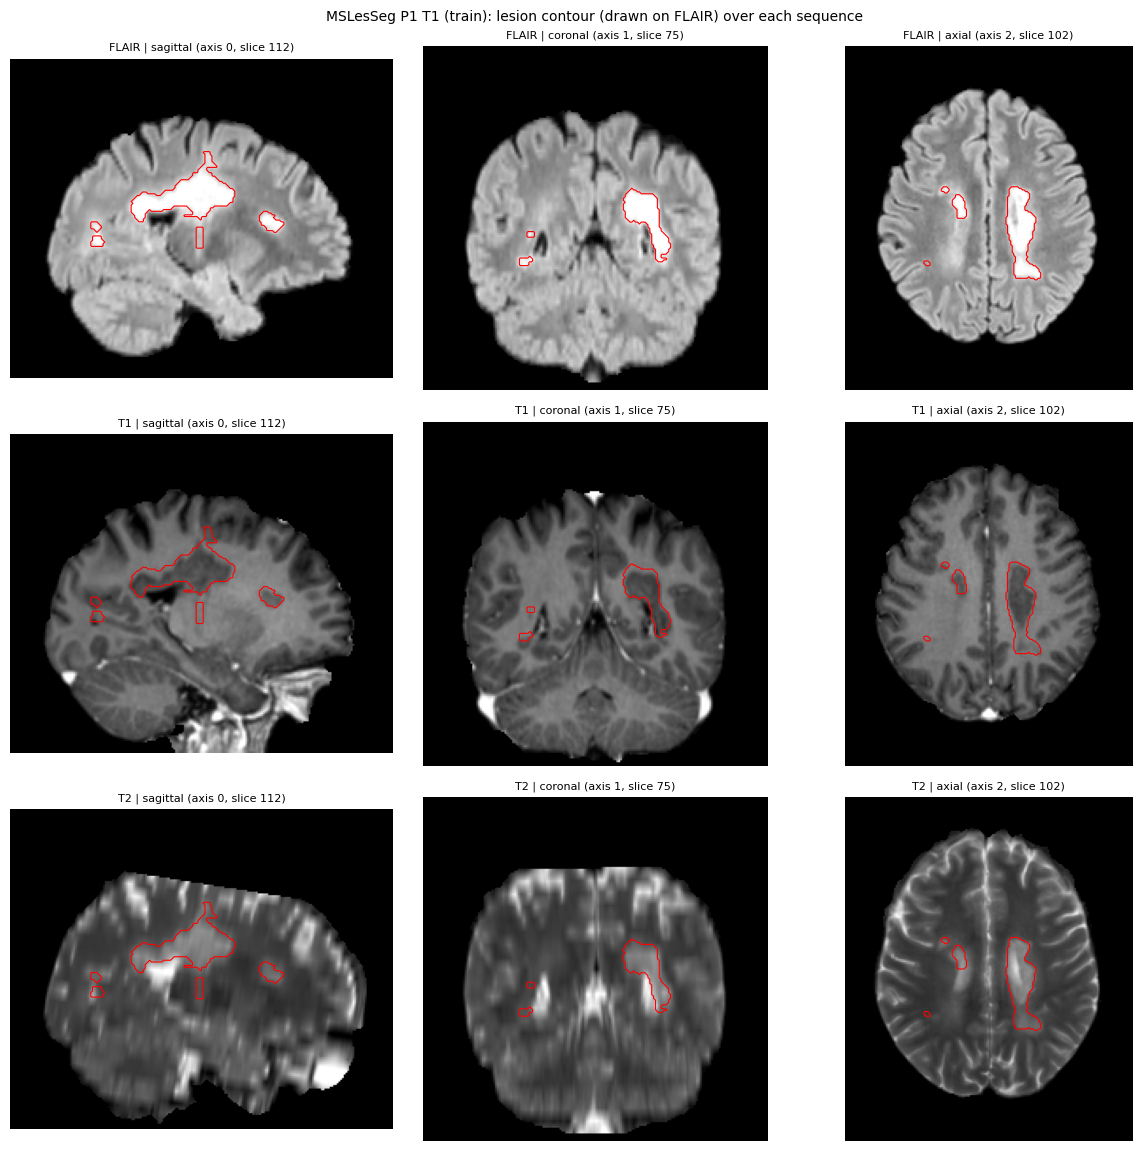

In [6]:
complete = wide.dropna(subset=need).copy()
assert len(complete) > 0, "No series with FLAIR, T1, T2 and MASK all present."
# natural order (P1, P2, ..., P10) instead of string order (P1, P10, P11, ...)
complete = (complete.reset_index().assign(_n=lambda d: d.pid.str[1:].astype(int))
            .sort_values(["_n", "tp"]).drop(columns="_n").set_index(["split", "pid", "tp"]))
first_idx = complete.index[0]
r = complete.loc[first_idx]
print(f"Case: split={first_idx[0]}, patient={first_idx[1]}, timepoint={int(first_idx[2])}\n")

vols, imgs = {}, {}
for seq in SEQS:
    img, v = load_vol(r[seq])
    imgs[seq], vols[seq] = img, v
    pos = v[brain_of(v)]
    print(f"{seq}: {r[seq].name}")
    print(f"  shape {v.shape} | dtype on disk {img.get_data_dtype()} | voxel mm {tuple(round(float(z), 3) for z in img.header.get_zooms()[:3])} | orientation {axcodes(img)}")
    print("  intensity: min %.1f  median(non-zero) %.1f  p99 %.1f  max %.1f  | nonzero voxels %d" %
          (v.min(), np.median(pos), np.percentile(pos, 99), v.max(), pos.size))

mimg, mask = load_mask(r["MASK"])
print(f"\nMASK: {r['MASK'].name}")
print("  shape", mask.shape, "| unique values", np.unique(mask).tolist(), "| orientation", axcodes(mimg))
print("  lesion voxels:", int((mask > 0).sum()), "=> %.2f mL" % ((mask > 0).sum() * np.prod(mimg.header.get_zooms()[:3]) / 1000))

print("\nCross-checks for this case")
for seq in SEQS:
    print(f"  {seq} vs MASK: shape equal {vols[seq].shape == mask.shape} | affine equal {np.allclose(imgs[seq].affine, mimg.affine, atol=1e-3)}")
print("  brain footprint agreement (Dice of voxels != 0): FLAIR-T1 %.3f | FLAIR-T2 %.3f" %
      (dice(brain_of(vols['FLAIR']), brain_of(vols['T1'])), dice(brain_of(vols['FLAIR']), brain_of(vols['T2']))))
print("Affine:\n", np.round(imgs["FLAIR"].affine, 3))

show_overlay_multi(vols, mask, axcodes(imgs["FLAIR"]),
                   title=f"MSLesSeg {first_idx[1]} T{int(first_idx[2])} ({first_idx[0]}): lesion contour (drawn on FLAIR) over each sequence")

## 7. Quality control on every series, all three sequences

**Per sequence** (prefixes `FLAIR_`, `T1_`, `T2_`):
- shape/affine agreement with the mask, finite values, number of non-zero ("brain") voxels, `degenerate` = blank/near-empty volume, fraction of negative voxels, median brain intensity (scale);
- `frac_mask_in_brain`: share of lesion voxels that sit on non-zero image voxels (flagged below 99 %);
- `contrast_z` (**local**): median intensity inside the lesions minus the median of a 3-voxel ring around them, in robust SDs of the ring. Expected **positive on FLAIR and T2** (hyperintense lesions); on **T1 the sign varies** (iso-intense lesions or dark "black holes"), so T1 is not judged by its sign;
- `align_gain`: **FLAIR** = |contrast| of the real mask minus |contrast| of the left-right mirrored mask (the masks were drawn on FLAIR, so this is a valid check there). **T1 / T2** = normalised mutual information with FLAIR minus the same after displacing the volume by 4 voxels. Since the masks were drawn on FLAIR, FLAIR-to-T1/T2 registration is what decides whether the mask also fits T1/T2.

**Per series:** lesion volume, lesion count (6/18/26-connectivity) and size, and `brain_dice_FLAIR_T1` / `brain_dice_FLAIR_T2`.

*Why v1's T1/T2 flags were misleading:* comparing lesion intensity with the **whole-brain mean** is dominated by CSF, which is dark on T1 and the brightest tissue on T2, and the **mirror test** fails because MS lesions are bilateral and periventricular, so the mirrored mask lands on similar tissue. These are heuristics for catching gross problems, not proof that annotations are correct.

In [ ]:
records = []
for k, (idx, r) in enumerate(complete.iterrows()):
    split, pid, tp = idx
    try:
        rec = qc_case({s: r[s] for s in SEQS}, r["MASK"], case_id=f"{pid}_T{int(tp)}")
    except Exception as e:
        rec = dict(case=f"{pid}_T{int(tp)}", error=repr(e))
    rec.update(split=split, pid=pid, tp=int(tp))
    records.append(rec)
    if (k + 1) % 10 == 0 or k + 1 == len(complete):
        print(f"  QC {k + 1}/{len(complete)}")

qc = pd.DataFrame(records)
if "error" in qc.columns and qc["error"].notna().any():
    print("\nCases that raised an error (not analysed):")
    print(qc.loc[qc["error"].notna(), ["case", "error"]].to_string(index=False))

def qcol(name):
    return qc[name] if name in qc.columns else pd.Series(np.nan, index=qc.index)

for s in SEQS:
    degenerate = qcol(f"{s}_degenerate").fillna(False).astype(bool)
    if s == "FLAIR":
        sus = (qcol("FLAIR_contrast_z") <= 0) | (qcol("FLAIR_align_gain") <= 0)
    elif s == "T2":
        sus = (qcol("T2_contrast_z") <= 0) | (qcol("T2_align_gain") <= NMI_GAIN_MIN)
    else:
        sus = qcol("T1_align_gain") <= NMI_GAIN_MIN          # T1 contrast sign is not informative
    qc[f"{s}_suspicious"] = sus.fillna(False) | degenerate
qc.drop(columns=["sizes_mm3"]).to_csv(OUT / "mslesseg_qc.csv", index=False)

print("\nMask-level summary (all series):")
print(qc[["lesion_ml", "lesion_pct_brain", "n_lesions", "median_lesion_mm3", "frac_small"]].describe().round(3).T)

print("\nPer-sequence summary (all series):")
per_seq = []
for s in SEQS:
    med = qcol(f"{s}_median_brain")
    per_seq.append(dict(
        sequence=s,
        median_brain_intensity_median=med.median(),
        intensity_scale_max_over_min=med.max() / med.min() if med.min() > 0 else np.nan,
        n_blank=int(qcol(f"{s}_degenerate").fillna(False).sum()),
        pct_with_negative_voxels=100 * (qcol(f"{s}_neg_frac") > 0).mean(),
        contrast_z_median=qcol(f"{s}_contrast_z").median(),
        pct_series_negative_contrast=100 * (qcol(f"{s}_contrast_z") < 0).mean(),
        align_gain_median=qcol(f"{s}_align_gain").median(),
        n_suspicious=int(qc[f"{s}_suspicious"].sum()),
        pct_lesion_voxels_in_brain_min=100 * qcol(f"{s}_frac_mask_in_brain").min()))
print(pd.DataFrame(per_seq).round(3).T.to_string(header=False))
print("\nBrain footprint agreement between sequences:")
print(qc[["brain_dice_FLAIR_T1", "brain_dice_FLAIR_T2"]].describe().round(4).T)

  QC 10/115
  QC 20/115
  QC 30/115
  QC 40/115
  QC 50/115
  QC 60/115


### 7b. Look at the odd cases directly
The summary tables only say *that* something is off. This cell lists *which* scans: blank or near-empty volumes, volumes with negative values, extreme intensity scales, lesions outside the image footprint, poor FLAIR-T1/T2 footprint agreement and failed registration controls. Open the worst ones with `show_overlay_multi` before deciding anything about them.

In [ ]:
show = ["case", "split"]
for s in SEQS:
    odd = qc[(qcol(f"{s}_degenerate").fillna(False).astype(bool)) | (qcol(f"{s}_frac_mask_in_brain") < MASK_IN_BRAIN_MIN)]
    print(f"\n[{s}] blank volumes or >1 % of lesion voxels outside the image: {len(odd)}")
    if len(odd):
        cols = show + [f"{s}_brain_vox", f"{s}_min", f"{s}_neg_frac", f"{s}_median_brain", f"{s}_frac_mask_in_brain"]
        print(odd[[c for c in cols if c in odd.columns]].round(4).to_string(index=False))
    low = qc.nsmallest(3, f"{s}_median_brain")[show + [f"{s}_median_brain", f"{s}_p99", f"{s}_brain_vox"]]
    high = qc.nlargest(3, f"{s}_median_brain")[show + [f"{s}_median_brain", f"{s}_p99", f"{s}_brain_vox"]]
    print(f"[{s}] lowest / highest median brain intensity (intensity scale is arbitrary per scan):")
    print(pd.concat([low, high]).round(1).to_string(index=False))

for other in ("T1", "T2"):
    c = f"brain_dice_FLAIR_{other}"
    print(f"\nWorst FLAIR-{other} brain-footprint agreement:")
    print(qc.nsmallest(5, c)[["case", "split", c, "FLAIR_brain_vox", f"{other}_brain_vox"]].round(3).to_string(index=False))
    g = f"{other}_align_gain"
    print(f"Lowest FLAIR-{other} registration gain (NMI aligned minus NMI displaced {SHIFT_VOX} voxels; <= {NMI_GAIN_MIN} = suspicious):")
    print(qc.nsmallest(5, g)[["case", "split", f"{other}_nmi_FLAIR", g]].round(4).to_string(index=False))

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, title) in zip(axs[0], [("lesion_ml", "lesion volume (mL)"), ("n_lesions", "lesion count (26-conn.)"),
                                      ("lesion_pct_brain", "lesion load (% of FLAIR brain voxels)")]):
    for sp, g in qc.groupby("split"):
        ax.hist(g[col].dropna(), bins=20, alpha=0.6, label=sp)
    ax.set_title(title, fontsize=10)
axs[0, 0].legend()
for ax, s in zip(axs[1], SEQS):
    for sp, g in qc.groupby("split"):
        ax.hist(g[f"{s}_contrast_z"].dropna(), bins=20, alpha=0.6, label=sp)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{s}: intensity inside mask vs brain (brain SD)", fontsize=10)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, s in zip(axs, SEQS):
    for sp, g in qc.groupby("split"):
        ax.hist(g[f"{s}_median_brain"].dropna(), bins=20, alpha=0.6, label=sp)
    ax.set_title(f"{s}: median brain intensity per scan", fontsize=10)
axs[0].legend()
plt.tight_layout(); plt.show()

# visual checks: largest lesion load, median, smallest non-empty, all three sequences each
nz = qc[qc.lesion_ml > 0].sort_values("lesion_ml")
picks = [nz.iloc[-1], nz.iloc[len(nz) // 2], nz.iloc[0]] if len(nz) else []
for rr in picks:
    r = complete.loc[(rr["split"], rr["pid"], rr["tp"])]
    vs = {s: load_vol(r[s])[1] for s in SEQS}
    img0 = nib.load(str(r["FLAIR"])); _, m = load_mask(r["MASK"])
    show_overlay_multi(vs, m, axcodes(img0), title=f"{rr['case']} ({rr['split']}), lesion volume {rr['lesion_ml']:.1f} mL")

### Lesion load by split, and a cross-check against the paper
The dataset paper (Table 1) reports, for the training set, mean lesion volume 12.167 (SD 13.233) and 28.9 (SD 19.2) lesions per patient, and for the test set 10.231 (SD 10.912) and 41.2 (SD 43.17). The unit is not stated in the paper. Our volumes are computed in **mL** (mm^3 / 1000) and reproduce the paper's means to three decimals, so the table is in **mL**. The paper's SDs are **population SDs (ddof = 0)**, while pandas defaults to ddof = 1, so use ddof = 0 when comparing. The lesion counts depend on the connectivity rule (not stated), so the cell below reports 6-, 18- and 26-connectivity; the one closest to the paper is probably what the authors used.

In [ ]:
by_split = qc.groupby("split").agg(
    series=("case", "count"), patients=("pid", "nunique"),
    lesion_ml_mean=("lesion_ml", "mean"), lesion_ml_sd=("lesion_ml", "std"),
    n_lesions_mean=("n_lesions", "mean"), n_lesions_sd=("n_lesions", "std"),
    pct_brain_median=("lesion_pct_brain", "median"), frac_small_mean=("frac_small", "mean")).round(2)
print(by_split)

sd0 = lambda x: float(np.std(x, ddof=0))
rows = []
for sp, g in qc.groupby("split"):
    ref = PAPER["table1"].get(sp)
    rows.append(dict(split=sp, quantity="volume mL (mean, SD ddof=0)", ours=f"{g.lesion_ml.mean():.3f} +- {sd0(g.lesion_ml):.3f}",
                     paper=f"{ref['vol'][0]} +- {ref['vol'][1]}" if ref else ""))
    for conn, c in ((6, "n_lesions_6"), (18, "n_lesions_18"), (26, "n_lesions")):
        rows.append(dict(split=sp, quantity=f"lesion count, {conn}-connectivity", ours=f"{g[c].mean():.1f} +- {sd0(g[c]):.1f}",
                         paper=f"{ref['n'][0]} +- {ref['n'][1]}" if ref else ""))
print("\nCross-check against paper Table 1:")
print(pd.DataFrame(rows).to_string(index=False))

## 8. Field strength (1.5T / 3T) and clinical / scanner metadata

The paper says the data come from scanners at 1.5T and 3T and that the release includes overview files with age, sex, acquisition date and scan details. The NIfTI headers cannot give the field strength (converted, registered, skull-stripped), so it has to come from the **metadata CSVs**.

**Why v1 got this wrong.** `clinical_data.csv` is **semicolon-separated with decimal commas** (`28,09`, `3,5`) and its header has a trailing `;`. Read with the default `sep=","` it collapsed to one column and the decimal commas were split into extra fields, which is why the output looked garbled and "no field-strength column" was concluded. v1 also stopped after the first CSV and never opened the three `patient_scanners_info_*.csv` files, which are the most likely place for scanner details. The cell below detects the delimiter, reads every metadata table as text, converts numbers explicitly, and prints what each file actually contains.

In [ ]:
def read_table(p):
    """Read a metadata table without guessing: detect the delimiter from the header line, keep everything as text,
    drop fully empty columns. Numeric conversion (decimal comma) is done explicitly afterwards."""
    if p.suffix.lower() in {".xlsx", ".xls"}:
        df = pd.read_excel(p, dtype=str); sep = "excel"
    else:
        with open(p, encoding="utf-8-sig", errors="replace") as f:
            head = f.readline()
        sep = max([";", ",", "\t"], key=head.count)
        df = pd.read_csv(p, sep=sep, dtype=str, encoding="utf-8-sig", index_col=False)
    df.columns = [c.strip() if isinstance(c, str) else c for c in df.columns]
    df = df.dropna(axis=1, how="all")
    return df, sep

def to_num(s):
    return pd.to_numeric(s.astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")

meta_files = sorted(p for p in MSLESSEG_ROOT.rglob("*")
                    if p.is_file() and p.suffix.lower() in {".csv", ".tsv", ".xlsx", ".xls"})
print("Metadata tables found:")
for p in meta_files: print("  ", p.relative_to(MSLESSEG_ROOT))

FIELD_RE = re.compile(r"tesla|field|strength|scanner|magnet|manufact|model|machine|device|coil|\bT\b|3T|1\.5", re.I)
tables = {}
for p in meta_files:
    try:
        df, sep = read_table(p)
    except Exception as e:
        print("could not read", p.name, repr(e)); continue
    tables[p.name] = df
    print(f"\n=== {p.name}  (sep={sep!r}, shape={df.shape}) ===")
    print("columns:", list(df.columns))
    print(df.head(4).to_string())
    hits = [c for c in df.columns if FIELD_RE.search(str(c))]
    for c in hits:
        print(f"\n  value counts for {str(c)!r}:")
        print(df[c].value_counts(dropna=False).head(10).to_string())
    if not hits:
        print("  (no column name looks like field strength / scanner; inspect the values above)")

### 8b. Cross-check the clinical table against the masks
`clinical_data.csv` lists lesion volume and lesion count per scan. If we computed the masks correctly, the clinical volume (mm^3) should be about `lesion_ml * 1000`. This also tells us which of the columns really holds the volume and which the count: in the printed rows the header has one name fewer than the rows have fields, so the last two numeric fields (e.g. `20674.0` and `18` for P1 T1) are likely *volume in mm^3* and *lesion count*, but the cell checks that numerically instead of assuming it.

In [ ]:
clin_name = next((n for n in tables if "clinical" in n.lower()), None)
if clin_name is None:
    print("No clinical_data table found; skipping the cross-check.")
else:
    clin = tables[clin_name].copy()
    clin = clin.rename(columns={c: ("extra_col" if str(c).startswith("Unnamed") else c) for c in clin.columns})
    clin["case"] = clin["Patient"].str.strip() + "_" + clin["Timepoint"].str.strip()
    num_cols = [c for c in clin.columns if c not in {"Patient", "Timepoint", "Sex", "MS Type", "case"}]
    for c in num_cols: clin[c] = to_num(clin[c])
    print("Clinical table after explicit parsing:")
    print(clin.drop(columns=["case"]).describe().round(2).T.to_string())
    print("\nMS type counts:", clin["MS Type"].value_counts().to_dict(), "| sex counts:", clin["Sex"].value_counts().to_dict())

    mrg = clin.merge(qc[["case", "split", "lesion_ml", "n_lesions", "n_lesions_18", "n_lesions_6"]], on="case", how="outer", indicator=True)
    print("\nRows only in clinical table / only in QC:", int((mrg["_merge"] == "left_only").sum()), "/", int((mrg["_merge"] == "right_only").sum()))
    both = mrg[mrg["_merge"] == "both"]
    for c in [c for c in ("Lesion Volume", "Lesion Number", "extra_col") if c in both.columns and both[c].notna().any()]:
        x = both[c]
        print(f"\n  column {c!r}: {int(x.notna().sum())} values")
        print(f"     vs lesion_ml*1000 : corr {np.corrcoef(x.dropna(), both.loc[x.notna(), 'lesion_ml'])[0, 1]:+.3f} | median ratio mask/clinical {np.median(both.loc[x.notna(), 'lesion_ml'] * 1000 / x.dropna()):.3f}")
        for k in ("n_lesions_6", "n_lesions_18", "n_lesions"):
            print(f"     vs {k:<13}: corr {np.corrcoef(x.dropna(), both.loc[x.notna(), k])[0, 1]:+.3f} | median diff {np.median(both.loc[x.notna(), k] - x.dropna()):+.1f}")
    print("\nA correlation near 1 and a ratio near 1.0 identifies the volume column (mm^3); the count column correlates with n_lesions.")

## 9. Data-quality observations (automatic + documented)

In [ ]:
obs = []
def add(cond, text):
    if cond: obs.append(text)

q = qc
add(not q["mask_binary"].all(), f"{int((~q['mask_binary']).sum())} masks contain values other than 0/1.")
add(q["mask_shape"].map(lambda s: s != EXPECTED_SHAPE).any(), f"{int(q['mask_shape'].map(lambda s: s != EXPECTED_SHAPE).sum())} masks do not have shape {EXPECTED_SHAPE}.")
add((q["lesion_ml"] == 0).any(), f"{int((q['lesion_ml'] == 0).sum())} masks are empty (no lesion voxels).")
add(len(df_native) > 0, f"{len(df_native)} files in the folder are NOT on the {EXPECTED_SHAPE} grid (original scanner-space copies, no masks); excluded.")
for s in SEQS:
    bad_shape = q[f"{s}_shape"].map(lambda t: t != EXPECTED_SHAPE)
    add(bad_shape.any(), f"{s}: {int(bad_shape.sum())} series do not have shape {EXPECTED_SHAPE}.")
    add((q[f"{s}_orient"] != EXPECTED_ORIENT).any(), f"{s}: {int((q[f'{s}_orient'] != EXPECTED_ORIENT).sum())} series are not in {EXPECTED_ORIENT} orientation.")
    add((~q[f"{s}_shape_match"]).any() or (~q[f"{s}_affine_match"]).any(), f"{s}: some series differ from their mask in shape or affine.")
    add((~q[f"{s}_finite"]).any(), f"{s}: {int((~q[f'{s}_finite']).sum())} volumes contain NaN/inf.")
    deg = qcol(f"{s}_degenerate").fillna(False).astype(bool)
    add(deg.any(), f"{s}: {int(deg.sum())} volumes are blank or nearly empty (< {MIN_BRAIN_VOX:,} non-zero voxels): {q.loc[deg, 'case'].tolist()[:10]}")
    neg = qcol(f"{s}_neg_frac") > 0
    add(neg.any(), f"{s}: {int(neg.sum())} volumes contain negative intensities (use `!= 0`, not `> 0`, to get the brain).")
    outside = qcol(f"{s}_frac_mask_in_brain") < MASK_IN_BRAIN_MIN
    add(outside.any(), f"{s}: {int(outside.sum())} masks have more than {100 * (1 - MASK_IN_BRAIN_MIN):.0f}% of lesion voxels on zero-valued {s} voxels "
        f"(worst {100 * (1 - qcol(f'{s}_frac_mask_in_brain').min()):.2f}%): {q.loc[outside, 'case'].tolist()[:10]}")
    add(q[f"{s}_suspicious"].any(), f"{s}: {int(q[f'{s}_suspicious'].sum())} cases fail the contrast/registration heuristics (see section 7b): {q.loc[q[f'{s}_suspicious'], 'case'].tolist()[:10]}")
    med = qcol(f"{s}_median_brain").dropna()
    add(len(med) > 3 and med.min() > 0 and med.max() / med.min() > 3,
        f"{s}: median brain intensity varies {med.max() / med.min():.1f}x between scans ({med.min():.0f} to {med.max():.0f}); intensities are not on a common scale, so per-volume normalisation is mandatory.")
for other in ("T1", "T2"):
    c = f"brain_dice_FLAIR_{other}"
    add(q[c].min() < BRAIN_DICE_MIN, f"FLAIR vs {other}: brain footprints agree poorly (Dice < {BRAIN_DICE_MIN}) in {int((q[c] < BRAIN_DICE_MIN).sum())} series (min {q[c].min():.3f}, median {q[c].median():.3f}); "
        "different BET runs per sequence are the likely reason; check registration / skull-stripping.")
add(q["frac_small"].mean() > 0.3, f"On average {100 * q['frac_small'].mean():.0f}% of lesions are smaller than {TINY_MM3:.0f} mm^3; Dice will under-represent them.")
t1neg = 100 * (q["T1_contrast_z"] < 0).mean()
print(f"INFO: lesions are darker than their surrounding ring on T1 in {t1neg:.0f}% of series (expected, T1 lesions are often hypointense); "
      f"on FLAIR in {100 * (q['FLAIR_contrast_z'] < 0).mean():.0f}% and on T2 in {100 * (q['T2_contrast_z'] < 0).mean():.0f}% (should be near 0%).\n")

print("AUTOMATIC FLAGS")
if obs:
    for i, o in enumerate(obs, 1): print(f" {i}. {o}")
else:
    print(" none raised")

print("""
DOCUMENTED IN THE DATASET PAPER (not detectable from the files)
 a. The volumes are on a 1 mm grid, but the original scans were thicker: mean slice thickness about 2.6 mm for FLAIR, about 1.1 mm for T1 and
    about 4.2 mm for T2. So FLAIR and especially T2 are interpolated (sharp in-plane, smooth through-plane); T1 is closest to true 1 mm detail.
 b. The scans did not follow one acquisition protocol (several scanners, 1.5T and 3T, some from private clinics). For T1 the reported TR and TE have
    standard deviations larger than their means, which suggests very different T1 sequence types were mixed; this is my reading of the table, not a statement of the paper.
 c. Masks were drawn on FLAIR by one junior rater and validated by two senior experts; the paper itself describes them both as 'single rater' and as
    'more experts', so treat the labels as single-rater with expert review. Lesion appearance on T1 and T2 is therefore a cross-check, not the annotation target.
""")

## 10. Summary for the report (auto-generated from the results above)

In [ ]:
seqs = sorted(set(df_files.seq) - {"MASK"})
print("DATASET CONFIRMATION")
print("  Dataset            : MSLesSeg (figshare doi 10.6084/m9.figshare.27919209), public, with expert lesion masks")
print("  Licence            : CC-BY-4.0 according to the dataset paper (verify on the figshare page)")
print("  Scope              : brain only; input = skull-stripped FLAIR / T1 / T2 volumes, output = binary lesion mask on the same grid")
print(f"  Patients           : {df_files.pid.nunique()} ({df_files.groupby('split').pid.nunique().to_dict()})")
print(f"  Excluded           : {len(df_native)} native-space files outside the {EXPECTED_SHAPE} grid (no masks)")
print(f"  Series (timepoints): {len(wide)}  (complete with all three sequences + mask: {len(complete)})")
print(f"  Sequences          : {seqs} + lesion mask (masks per split: {has_mask.groupby(level='split').sum().to_dict()})")
print(f"  Test masks released: {TEST_MASKS_RELEASED}")
for s in SEQS:
    sub = inv[inv.seq == s]
    print(f"  {s:<5} dimensions   : {dict(Counter(sub['shape']))} | voxel {dict(Counter(sub['zooms']))} | orientation {dict(Counter(sub['orient']))}")
ex = complete.index[0]
print(f"  Volumes loaded     : {ex[1]} timepoint {int(ex[2])} ({ex[0]}) -> FLAIR/T1/T2 {vols['FLAIR'].shape}, mask {int((mask > 0).sum())} lesion voxels")
print(f"  Lesion load        : median {qc['lesion_ml'].median():.1f} mL, median {qc['n_lesions'].median():.0f} lesions per scan (26-connectivity)")
for s in SEQS:
    print(f"  {s:<5} lesion contrast: median {qc[f'{s}_contrast_z'].median():+.2f} brain SD | median brain intensity {qc[f'{s}_median_brain'].median():.0f} "
          f"(max/min across scans {qc[f'{s}_median_brain'].max() / max(qc[f'{s}_median_brain'].min(), 1e-9):.1f}x)")
print("  Data-quality note  :", obs[0] if obs else "no automatic flag; see documented points (interpolated 1 mm grid, mixed protocols)")
print("\nTables saved to:", OUT.resolve())